## Modélisation du projet African Crop Yield Intelligence

Ce notebook relève de la phase Modeling de CRISP-DM. Il compare les variantes d'un modèle de rendement sur le seul développement et justifie le modèle retenu pour `regional` et pour `survey`. Les ensembles de test ne sont pas utilisés. La sélection a été figée dans `src/models/selection.py` avant toute évaluation sur ces ensembles.

**Technique retenue**

Le modèle prédit le logarithme du rendement par gradient boosting sur arbres de décision, avec LightGBM. Les arbres captent les interactions entre culture, climat et sol, traitent les précipitations manquantes avant 2001 sans imputation et acceptent les variables catégorielles. La perte est l'erreur absolue, qui correspond à la métrique principale `mae_log`.

**Variables**

- Pour `regional`, la culture, la saison, le pays, la source, le niveau administratif, le système de production, l'année de récolte, les coordonnées et la surface de la zone, le calendrier, les douze indicateurs climatiques, les neuf variables de sol et les deux variables de relief.
- Pour `survey`, la culture, le pays, l'année de récolte, la position de la grappe et les mêmes variables de calendrier, de climat, de sol et de relief.
- Aucune colonne classée comme fuite dans `docs/data_dictionary.md` n'est utilisée. La surface GPS des parcelles, dénominateur de la cible, en fait partie.

**Préalable**

Les expériences sont calculées par `python -m src.models.experiences regional` et `python -m src.models.experiences survey`, qui écrivent leurs prédictions dans `data/interim/modeles` en deux heures environ. Le notebook relit ces prédictions et s'exécute en deux minutes.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.models.bilan import bilan_schema, erreurs_absolues, part_expliquee_climat
from src.models.donnees import NUMERIQUES_REGIONAL, NUMERIQUES_SURVEY, VARIABLES_PLUIE, table_regional
from src.models.experiences import (
    JEUX, SCHEMAS, VARIANTES_TEMPORELLES, charger_table, experiences_regional, experiences_survey, lire_experience,
)
from src.models.selection import VARIANTES_RETENUES, configuration_retenue, courbes_retenues

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
tables = {jeu: charger_table(jeu) for jeu in JEUX}
developpements = {jeu: t[t["partition"] == "developpement"] for jeu, t in tables.items()}
experiences = {"regional": experiences_regional(), "survey": experiences_survey()}


def bilan(jeu, schema):
    noms = [n for n in experiences[jeu] if not n.endswith("_fin")] if schema == "croisee" else [
        n for n in VARIANTES_TEMPORELLES if n in experiences[jeu] and not n.endswith("_fin")]
    return bilan_schema(jeu, schema, developpements[jeu], JEUX[jeu][0], noms)

### 1. Tests unitaires

Les tests des modèles vérifient la durée de saison, le codage stable des modalités, l'erreur par nombre d'arbres, l'absence de chevauchement entre entraînement et évaluation dans la validation croisée et les découpages temporels internes.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 95 tests in 1.593s', '', 'OK']


### 2. Tables de modélisation

Les tables réunissent la cible, les partitions du protocole et les variables explicatives. Pour `regional`, les récoltes antérieures à 1981 et les lignes dont la surface récoltée dépasse celle de la zone sont écartées, conformément aux décisions antérieures.

In [3]:
complete, retenue = table_regional()
print("regional :", len(complete), "lignes | retenues :", int(retenue.sum()),
      "| récoltes antérieures à 1981 :", int((complete["harvest_year"] < 1981).sum()),
      "| surface supérieure à la zone :", int(complete["flag_surface_superieure_zone"].sum()))
for jeu, table in tables.items():
    numeriques = NUMERIQUES_REGIONAL if jeu == "regional" else NUMERIQUES_SURVEY
    print(jeu, ":", table["partition"].value_counts().to_dict())
    manquants = table[numeriques].isna().mean().sort_values(ascending=False)
    print("  variables les plus souvent manquantes :", manquants.head(5).round(3).to_dict())
annee = developpements["regional"]["harvest_year"]
print("Développement de regional, part des lignes sans pluie :", round(developpements["regional"]["pluie_cumul"].isna().mean(), 3),
      "| dont récoltes postérieures à 2000 :", round(developpements["regional"].loc[annee > 2000, "pluie_cumul"].isna().mean(), 4))

regional : 145877 lignes | retenues : 142247 | récoltes antérieures à 1981 : 3542 | surface supérieure à la zone : 88
regional : {'developpement': 103075, 'test_spatial': 22843, 'test_temporel': 13221, 'test_spatio_temporel': 3108}
  variables les plus souvent manquantes : {'pluie_jours': 0.285, 'pluie_cumul': 0.285, 'bilan_hydrique': 0.285, 'sequence_seche_max': 0.285, 'et0_cumul': 0.02}
survey : {'developpement': 82293, 'test_temporel': 39093, 'test_spatial': 20503, 'test_spatio_temporel': 9249}
  variables les plus souvent manquantes : {'azote_0_30': 0.008, 'bilan_hydrique': 0.008, 'sequence_seche_max': 0.008, 'pluie_jours': 0.008, 'degres_jours': 0.008}
Développement de regional, part des lignes sans pluie : 0.319 | dont récoltes postérieures à 2000 : 0.0067


**Constat**

- `regional` conserve 142 247 lignes sur 145 877, dont 103 075 en développement. 3 542 récoltes antérieures à 1981 et 88 lignes de surface aberrante sont écartées.
- La pluie manque pour 31,9 % des lignes du développement de `regional`, presque toutes antérieures à 2001, et pour 0,67 % des récoltes postérieures à 2000.
- Dans `survey`, aucune variable ne manque pour plus de 0,8 % des lignes.

**Conséquences pour la suite**

Les effectifs des partitions sont ceux du protocole, diminués des lignes écartées. La référence est recalculée sur les mêmes lignes que les modèles.

### 3. Validation croisée du protocole

Chaque variante est évaluée par la validation croisée à cinq plis groupés du protocole, à son meilleur nombre d'arbres. L'écart au modèle complet est positif lorsque la variante fait moins bien. Son intervalle de confiance à 95 % est obtenu par bootstrap des groupes, puisque les lignes d'un même groupe ne sont pas indépendantes.

In [4]:
for jeu in JEUX:
    print(jeu)
    display(bilan(jeu, "croisee").round(4))

regional


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,103075.0,2000.0,0.3579,0.1409,0.0000,0.0000,0.0000
perte_l2,103075.0,1300.0,0.3620,0.1310,0.0041,0.0020,0.0063
sans_climat,103075.0,2000.0,0.3570,0.1430,-0.0008,-0.0028,0.0008
sans_sols_relief,103075.0,2000.0,0.3572,0.1426,-0.0007,-0.0040,0.0026
sans_source,103075.0,2000.0,0.3584,0.1396,0.0005,-0.0007,0.0019
sans_pays,103075.0,2000.0,0.3670,0.1189,0.0092,0.0068,0.0119
sans_annee,103075.0,2000.0,0.3696,0.1128,0.0117,0.0094,0.0143
entrainement_depuis_2001,103075.0,1400.0,0.3920,0.0591,0.0341,0.0276,0.0411
feuilles_31,103075.0,2000.0,0.3588,0.1386,0.0010,-0.0001,0.0021
feuilles_127,103075.0,2000.0,0.3580,0.1406,0.0002,-0.0011,0.0015


survey


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,82293.0,200.0,0.7181,0.0697,0.0000,0.0000,0.0000
perte_l2,82293.0,300.0,0.7207,0.0662,0.0027,0.0011,0.0043
sans_climat,82293.0,200.0,0.7187,0.0689,0.0006,-0.0009,0.0021
sans_sols_relief,82293.0,200.0,0.7210,0.0659,0.0029,0.0012,0.0047
sans_pays,82293.0,200.0,0.7194,0.0679,0.0014,0.0002,0.0025
sans_annee,82293.0,200.0,0.7240,0.0620,0.0059,0.0042,0.0077
feuilles_31,82293.0,400.0,0.7180,0.0698,-0.0001,-0.0013,0.0011
feuilles_min_200,82293.0,200.0,0.7182,0.0695,0.0001,-0.0009,0.0012
reference,82293.0,NaN,0.7718,0.0000,NaN,NaN,NaN


**Constat**

- Dans `regional`, le modèle complet atteint 0,358 contre 0,417 pour la référence, soit une compétence de 14,1 %. Dans `survey`, il atteint 0,718 contre 0,772, soit 7,0 %.
- Retirer l'année ou le pays dégrade nettement les deux jeux. La perte quadratique fait moins bien que la perte absolue, et la complexité des arbres change peu le résultat.
- Retirer le climat, les sols et le relief ou la source ne change pas significativement l'erreur de `regional`. Dans `survey`, les sols et le relief améliorent l'erreur de 0,003 et le climat reste sans effet.

**Analyse**

La validation croisée tient à l'écart des régions, mais pas des années. Pour prédire une région du Malawi en 1992, le modèle a appris sur les autres régions du Malawi en 1992. Le croisement du pays et de l'année lui donne directement le choc de cette année, sans passer par le climat. Ce schéma sous-estime donc la valeur du climat pour une année future, pour laquelle aucune information contemporaine n'existe. Le protocole signalait cette limite à sa section 9, et la section 7 de ce notebook la lève.

### 4. Précipitations manquantes avant 2001

Deux options étaient ouvertes depuis l'acquisition du climat, conserver les récoltes antérieures à 2001 sans précipitations ou restreindre l'entraînement aux récoltes postérieures. Les deux sont comparées sur les mêmes lignes évaluées.

In [5]:
dev = developpements["regional"]
reel = dev["yieldTonHa"]
recent = dev["harvest_year"] >= 2001
lignes = {}
for nom in ["complet", "entrainement_depuis_2001", "sans_climat"]:
    predictions = lire_experience("regional", "croisee", nom).reindex(dev.index)
    meilleur = (np.abs(np.log(predictions).sub(np.log(reel), axis=0))).mean().idxmin()
    erreur = erreurs_absolues(reel, predictions[meilleur])
    lignes[nom] = {"depuis 2001": erreur[recent.to_numpy()].mean(), "avant 2001": erreur[~recent.to_numpy()].mean()}
erreur = erreurs_absolues(reel, lire_experience("regional", "croisee", "reference").reindex(dev.index))
lignes["reference"] = {"depuis 2001": erreur[recent.to_numpy()].mean(), "avant 2001": erreur[~recent.to_numpy()].mean()}
print("Lignes du développement depuis 2001 :", int(recent.sum()), "| avant 2001 :", int((~recent).sum()))
display(pd.DataFrame(lignes).T.round(4))

Lignes du développement depuis 2001 : 69487 | avant 2001 : 33588


,depuis 2001,avant 2001
complet,0.3653,0.3424
entrainement_depuis_2001,0.3647,0.4484
sans_climat,0.3646,0.3414
reference,0.4229,0.4034


**Constat**

- Sur les 69 487 lignes postérieures à 2000, l'entraînement restreint donne 0,365, comme le modèle complet.
- Sur les 33 588 lignes antérieures, il donne 0,448, contre 0,342 pour le modèle complet.

**Décision**

Toutes les récoltes postérieures ou égales à 1981 sont conservées, avec des précipitations manquantes avant 2001. La restriction n'apporte rien aux années récentes et prive le modèle des années anciennes.

### 5. Calendriers, sources et niveaux

Les erreurs du modèle complet et de la référence sont ventilées par origine du calendrier, par source et par niveau administratif, en validation croisée.

In [6]:
predictions = lire_experience("regional", "croisee", "complet").reindex(dev.index)[2000]
comparaison = dev.assign(
    modele=erreurs_absolues(reel, predictions),
    reference=erreurs_absolues(reel, lire_experience("regional", "croisee", "reference").reindex(dev.index)),
    biais_log=np.log(predictions) - np.log(reel),
)
for colonne in ["source_calendrier", "Source", "level"]:
    strates = comparaison.groupby(comparaison[colonne].astype("string").fillna("aucun")).agg(
        lignes=("modele", "size"), modele=("modele", "mean"), reference=("reference", "mean"), biais_log=("biais_log", "mean"))
    strates["competence"] = 1 - strates["modele"] / strates["reference"]
    display(strates.round(3))

,lignes,modele,reference,biais_log,competence
source_calendrier,,,,,
aucun,163,0.297,0.245,-0.075,-0.210
ggcmi,2464,0.359,0.372,0.062,0.034
ligne,84038,0.366,0.421,0.020,0.129
niveau_1,4390,0.322,0.432,-0.008,0.254
niveau_1_dominant,1201,0.371,0.419,0.029,0.115
pays,919,0.419,0.455,0.081,0.081
pays_dominant,97,0.294,0.324,0.072,0.092
zone,9803,0.296,0.387,-0.004,0.236


,lignes,modele,reference,biais_log,competence
Source,,,,,
AgroMAPS,8152,0.258,0.323,0.025,0.202
FAO_subnational,5056,0.361,0.470,-0.014,0.232
HarvestStat,84038,0.366,0.421,0.020,0.129
RCeA,5757,0.374,0.444,0.010,0.158
USAID_KadunaState,72,0.338,0.417,-0.121,0.190


,lignes,modele,reference,biais_log,competence
level,,,,,
1,39534,0.335,0.405,0.010,0.173
2,63541,0.372,0.424,0.023,0.122


**Constat**

- Le modèle bat la référence pour toutes les origines du calendrier sauf les 163 lignes sans calendrier, qui n'ont ni climat ni mois. Sur les 2 464 lignes au calendrier GGCMI, la compétence vaut 3,4 %, contre 12,9 % pour les lignes au calendrier propre.
- Le modèle bat la référence pour chaque source, de 12,9 % pour `HarvestStat` à 23,2 % pour `FAO_subnational`, et ses biais logarithmiques restent compris entre -0,014 et 0,025, sauf pour les 72 lignes de `USAID_KadunaState`. Le biais de -0,249 que le protocole relevait pour la référence sur `FAO_subnational` disparaît.
- La compétence vaut 17,3 % au niveau 1 et 12,2 % au niveau 2.

**Analyse**

Les lignes au calendrier GGCMI ne dégradent pas le modèle, mais en profitent moins. Le calendrier moins fiable affaiblit leurs variables climatiques, ce qui est cohérent avec la fiabilité de 55 % mesurée dans `06_climate_variables.ipynb`.

**Décision**

Les lignes au calendrier GGCMI sont conservées.

### 6. Part du climat dans la variation annuelle

Pour comprendre la faible contribution du climat, la part de la variation annuelle du rendement qu'il peut expliquer est mesurée directement. Le logarithme du rendement et les variables climatiques sont débarrassés, série par série, de leur moyenne et de leur tendance, sur les séries d'au moins dix récoltes postérieures à 2000. La part expliquée est le coefficient de détermination d'une régression des écarts du rendement sur les écarts climatiques et leurs carrés. Calculée sur les données ajustées, elle majore la part prévisible.

In [7]:
variables = ["pluie_cumul", "bilan_hydrique", "sequence_seche_max", "tmax_moyenne", "degres_jours_30", "dpv_moyen",
             "rayonnement_moyen", "pluie_jours"]
strates = {"ensemble": lambda d: np.ones(len(d), bool)}
strates.update({c: (lambda d, c=c: d["crop"] == c) for c in ["Maize", "Sorghum", "Millet", "Rice", "Beans", "Cassava"]})
strates.update({p: (lambda d, p=p: d["country"] == p) for p in ["South Africa", "Niger", "Malawi", "Zambia", "Kenya", "Ethiopia"]})
display(part_expliquee_climat(dev, variables, strates=strates).round(3))

,lignes,series,part_expliquee,ecart_type_anomalie
ensemble,44481.0,3261.0,0.017,0.361
Maize,6826.0,480.0,0.035,0.298
Sorghum,4838.0,351.0,0.035,0.351
Millet,3815.0,260.0,0.053,0.312
Rice,3401.0,242.0,0.025,0.341
Beans,2215.0,175.0,0.032,0.378
Cassava,2236.0,159.0,0.027,0.309
South Africa,549.0,35.0,0.260,0.183
Niger,1785.0,135.0,0.131,0.360
Malawi,3119.0,239.0,0.081,0.395


**Constat**

- Sur 44 481 récoltes de 3 261 séries, le climat explique 1,7 % de la variation annuelle du rendement, dont l'écart-type vaut 0,361 en logarithme.
- La part varie de 2,5 à 5,3 % selon la culture. Elle atteint 26,0 % en Afrique du Sud, 13,1 % au Niger et 8,1 % au Malawi, mais 1,9 % en Éthiopie.

**Analyse**

- La variation annuelle des rendements infranationaux est dominée par des facteurs que le climat de saison ne décrit pas, comme les erreurs des statistiques, les pratiques, les prix, les ravageurs ou les conflits. Le climat explique davantage là où les statistiques sont réputées fiables et la production sensible à la pluie, comme en Afrique du Sud et au Sahel.
- Le gain que peut apporter le climat est donc borné par les données elles-mêmes, et non par le modèle.

### 7. Validation temporelle interne

Pour mesurer la prédiction d'années futures sans toucher aux tests, deux schémas complètent la validation croisée sur le développement.

- La validation temporelle interne entraîne sur les récoltes antérieures à 2012 et évalue sur 2012 à 2016 pour `regional`. Pour `survey`, elle évalue la dernière vague de développement des sept pays qui en comptent au moins deux.
- La validation spatio-temporelle interne évalue les mêmes années récentes, pli par pli, avec un modèle qui n'a vu ni ces années ni ces groupes.

Ces schémas étendent le protocole sans en modifier les ensembles de test.

In [8]:
for jeu in JEUX:
    for schema in ["temporelle", "spatio_temporelle"]:
        print(jeu, schema)
        display(bilan(jeu, schema).round(4))

regional temporelle


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,24371.0,1800.0,0.3723,0.1376,0.0000,0.0000,0.0000
sans_climat,24371.0,1500.0,0.3752,0.1310,0.0028,-0.0008,0.0068
sans_sols_relief,24371.0,2000.0,0.3791,0.1218,0.0068,0.0021,0.0120
sans_pays,24371.0,2000.0,0.3937,0.0880,0.0214,0.0097,0.0377
sans_annee,24371.0,1800.0,0.3934,0.0887,0.0211,0.0124,0.0294
sans_source,24371.0,1900.0,0.3752,0.1309,0.0029,0.0004,0.0056
reference,24371.0,NaN,0.4317,0.0000,NaN,NaN,NaN


regional spatio_temporelle


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,24371.0,400.0,0.4256,0.1210,0.0000,0.0000,0.0000
sans_climat,24371.0,500.0,0.4286,0.1148,0.0030,-0.0017,0.0079
sans_sols_relief,24371.0,600.0,0.4197,0.1333,-0.0060,-0.0109,-0.0011
sans_pays,24371.0,600.0,0.4478,0.0752,0.0222,0.0101,0.0366
sans_annee,24371.0,400.0,0.4393,0.0929,0.0136,0.0046,0.0219
sans_source,24371.0,500.0,0.4282,0.1156,0.0026,0.0000,0.0055
reference,24371.0,NaN,0.4842,0.0000,NaN,NaN,NaN


survey temporelle


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,19204.0,100.0,0.7674,0.0271,0.0000,0.0000,0.0000
sans_climat,19204.0,100.0,0.7567,0.0405,-0.0106,-0.0158,-0.0053
sans_sols_relief,19204.0,100.0,0.7735,0.0193,0.0061,0.0025,0.0096
sans_pays,19204.0,200.0,0.7682,0.0260,0.0008,-0.0030,0.0046
sans_annee,19204.0,100.0,0.7771,0.0147,0.0098,0.0068,0.0125
reference,19204.0,NaN,0.7887,0.0000,NaN,NaN,NaN


survey spatio_temporelle


,lignes,meilleur_palier,mae_log,competence,ecart_au_complet,ic_bas,ic_haut
complet,19204.0,100.0,0.7649,0.0372,0.0000,0.0000,0.0000
sans_climat,19204.0,100.0,0.7579,0.0460,-0.0070,-0.0110,-0.0024
sans_sols_relief,19204.0,100.0,0.7751,0.0245,0.0101,0.0063,0.0142
sans_pays,19204.0,100.0,0.7749,0.0247,0.0100,0.0062,0.0141
sans_annee,19204.0,100.0,0.7837,0.0136,0.0188,0.0146,0.0228
reference,19204.0,NaN,0.7945,0.0000,NaN,NaN,NaN


**Constat**

- Dans `regional`, le modèle complet atteint 0,372 en validation temporelle et 0,426 en validation spatio-temporelle, contre 0,432 et 0,484 pour la référence. Retirer le climat ou la source le dégrade de 0,003 dans les deux schémas. Seul l'écart de la source en validation temporelle est significatif, l'intervalle de celui du climat contenant zéro. Retirer les sols et le relief le dégrade de 0,007 en validation temporelle et l'améliore de 0,006 en validation spatio-temporelle, deux écarts significatifs.
- Dans `survey`, retirer le climat améliore l'erreur de 0,011 en validation temporelle et de 0,007 en validation spatio-temporelle, deux écarts significatifs. Le modèle complet n'y bat la référence que de 2,7 et 3,7 %.
- Dans `survey`, les meilleurs nombres d'arbres tombent à 100, borne inférieure de la grille initiale. Une grille de 20 à 400 arbres a donc été ajoutée.

**Analyse**

- Dans `regional`, le climat apporte une information modeste mais réelle pour les années futures, conformément à la section 6. L'effet des sols et du relief dépend du schéma et s'annule en moyenne.
- Dans `survey`, le climat varie seulement d'une zone et d'une vague à l'autre, et chaque pays ne compte que deux à sept vagues. Le modèle utilise alors le climat pour reconnaître les vagues plutôt que pour apprendre une réponse au climat, ce qui nuit aux vagues futures. Le surapprentissage rapide, au-delà d'une centaine d'arbres, va dans le même sens.

### 8. Sélection

La variante retenue pour chaque jeu est celle qu'aucun schéma ne désavantage durablement. Son nombre d'arbres minimise la moyenne non pondérée des erreurs des trois schémas, ce qui équilibre la prédiction de lieux nouveaux, d'années futures et des deux.

regional : variante complet | 2000 arbres | catégorielles ['crop', 'saison', 'country', 'Source', 'level', 'crop_production_system'] | 30 numériques | perte l1


,croisee,temporelle,spatio_temporelle,moyenne
2000,0.3579,0.3723,0.4277,0.386


survey : variante sans_climat_fin | 100 arbres | catégorielles ['Crop', 'Country'] | 17 numériques | perte l1


,croisee,temporelle,spatio_temporelle,moyenne
100,0.719,0.7567,0.7579,0.7446


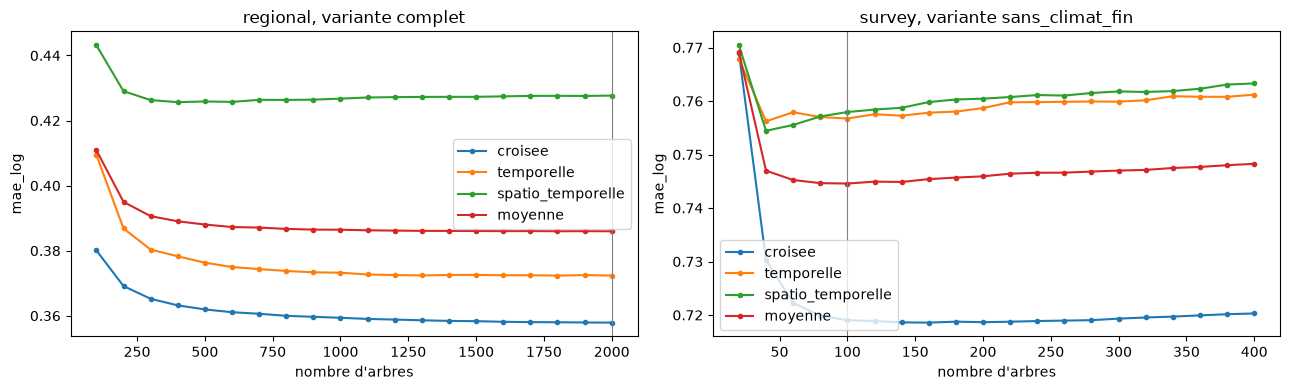

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for axe, jeu in zip(axes, JEUX):
    courbes = courbes_retenues(jeu, developpements[jeu])
    courbes.plot(ax=axe, marker=".")
    categorielles, numeriques, parametres, iterations = configuration_retenue(jeu, developpements[jeu])
    axe.axvline(iterations, color="grey", lw=0.8)
    axe.set_title(f"{jeu}, variante {VARIANTES_RETENUES[jeu]}")
    axe.set_xlabel("nombre d'arbres")
    axe.set_ylabel("mae_log")
    print(jeu, ": variante", VARIANTES_RETENUES[jeu], "|", iterations, "arbres | catégorielles", categorielles,
          "|", len(numeriques), "numériques | perte", parametres["objective"])
    display(courbes.loc[[iterations]].round(4))
plt.tight_layout()
plt.show()

**Décisions**

- Pour `regional`, le modèle complet est retenu avec 2 000 arbres. Son erreur moyenne sur les trois schémas vaut 0,386, avec 0,358 en validation croisée, 0,372 en validation temporelle et 0,428 en validation spatio-temporelle.
- Pour `survey`, le modèle sans variables climatiques est retenu avec 100 arbres. Son erreur moyenne vaut 0,745, avec 0,719 en validation croisée, 0,757 en validation temporelle et 0,758 en validation spatio-temporelle. Les courbes montrent un plateau de 60 à 140 arbres, et le choix ne dépend plus d'une borne de la grille.
- Ces choix sont figés dans `src/models/selection.py` avant l'évaluation des ensembles de test.

### 9. Synthèse

**Résultats**

| Élément | `regional` | `survey` |
|---|---|---|
| Variante retenue | Modèle complet | Modèle sans climat |
| Nombre d'arbres | 2 000 | 100 |
| Validation croisée, modèle et référence | 0,358 et 0,417 | 0,719 et 0,772 |
| Validation temporelle interne | 0,372 et 0,432 | 0,757 et 0,789 |
| Validation spatio-temporelle interne | 0,428 et 0,484 | 0,758 et 0,795 |

**Limites**

- Le climat explique au plus 1,7 % de la variation annuelle des rendements de `regional`, ce qui borne le gain qu'un modèle peut en tirer.
- La validation temporelle interne de `survey` repose sur sept pays et une vague chacun.
- Les intervalles de confiance ne tiennent pas compte de la corrélation entre groupes voisins ni entre années d'un même pays.
- La sélection du nombre d'arbres et de la variante utilise les mêmes validations que les scores rapportés ici, qui sont donc légèrement optimistes. Les ensembles de test en donneront une mesure indépendante.